## 1. Load the SMS Dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/SMSSpamCollection", sep="\t", header=None,
                  names=["label", "text"], quoting=3)

print("All messages:", len(raw))

All messages: 5574


## 2. Basic Statistics

The first 5 rows of the dataset, right now it two col. label and text. total number of rows in this tabular data is 5574.

In [2]:
raw.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
raw.describe()

,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


## 3. How much is spam?
The graph shows that 13.4% of the data is composed of Spam messages, the remaning is non-spam.

In [4]:
print(raw["label"].value_counts())

spam_share = (raw["label"] == "spam").mean() * 100
print(f"Spam is {spam_share:.1f}% of the messages")

label
ham     4827
spam     747
Name: count, dtype: int64
Spam is 13.4% of the messages


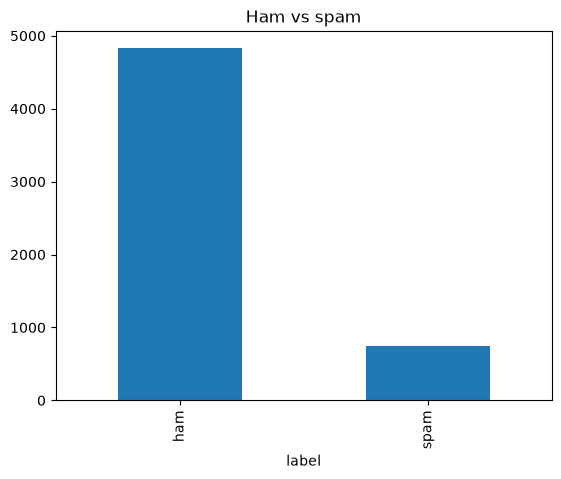

In [5]:
raw["label"].value_counts().plot(kind="bar")
plt.title("Ham vs spam")
plt.show()

## 4. Messages at both Spam and Ham

Just by visual inspection, We can tell that most spam messages have a "free" keyword, while ham messages is much natural conversation.

In [6]:
raw[raw["label"] == "spam"].head(10)

,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."
12,spam,URGENT! You have won a 1 week FREE membership ...
15,spam,"XXXMobileMovieClub: To use your credit, click ..."
19,spam,England v Macedonia - dont miss the goals/team...
34,spam,Thanks for your subscription to Ringtone UK yo...
42,spam,07732584351 - Rodger Burns - MSG = We tried to...


In [7]:
raw[raw["label"] == "ham"].head(10)

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
10,ham,I'm gonna be home soon and i don't want to tal...
13,ham,I've been searching for the right words to tha...
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!
16,ham,Oh k...i'm watching here:)


## 5. Message length

In [8]:
raw["length"] = raw["text"].str.len()
raw.groupby("label")["length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4827.0,71.471929,58.326643,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.676037,28.871250,13.0,133.0,149.0,157.0,223.0


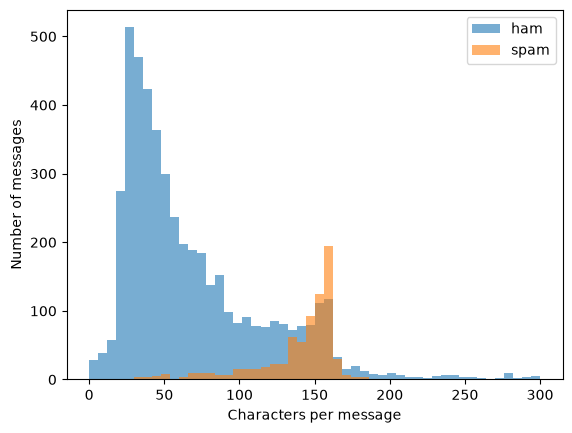

In [9]:
ham = raw[raw["label"] == "ham"]
spam = raw[raw["label"] == "spam"]

plt.hist(ham["length"], bins=50, range=(0, 300), alpha=0.6, label="ham")
plt.hist(spam["length"], bins=50, range=(0, 300), alpha=0.6, label="spam")
plt.xlabel("Characters per message")
plt.ylabel("Number of messages")
plt.legend()
plt.show()

## 6. Most repeated words in spam

In [10]:
spam_words = spam["text"].str.lower().str.split().explode()
spam_words.value_counts().head(10)

text
to      685
a       375
call    342
your    263
you     252
the     204
for     201
or      188
free    180
2       169
Name: count, dtype: int64

## 7. Load the two classifiers and the test messages

In [ ]:
import sys
sys.path.insert(0, "..")

import time
import joblib
from dotenv import load_dotenv

load_dotenv("../.env")

import ml_classifier
import llm_classifier

train_data, test_data = ml_classifier.load_train_test()
print("Train messages:", len(train_data))
print("Test messages: ", len(test_data))

Train messages: 4136
Test messages:  1035


## 8. ML classifier on the test messages

In [12]:
ml_model = joblib.load(ml_classifier.MODEL_FILE)   # trained by ml_classifier.py

start = time.time()
ml_predictions = []

for text in test_data["text"]:
    prediction = ml_model.predict([text])
    ml_predictions.append(prediction[0])

ml_seconds = time.time() - start

## 9. LLM classifier on the test messages

This asks the LLM on Amazon Bedrock one message at a time, so it takes about 9 minutes.

In [13]:
start = time.time()
llm_predictions = []

for text in test_data["text"]:
    prediction = llm_classifier.predict(text)
    llm_predictions.append(prediction)

llm_seconds = time.time() - start

print("Answers that were not spam or ham:", llm_predictions.count("unparsed"))

Answers that were not spam or ham: 0


## 10. Scores side by side

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

truth = test_data["label"]

scores = pd.DataFrame({
    "ML (LogReg)": [
        accuracy_score(truth, ml_predictions),
        precision_score(truth, ml_predictions, pos_label="spam"),
        recall_score(truth, ml_predictions, pos_label="spam"),
        f1_score(truth, ml_predictions, pos_label="spam"),
        ml_seconds / len(test_data) * 1000,
    ],
    "LLM (Bedrock Gemma 3 12B)": [
        accuracy_score(truth, llm_predictions),
        precision_score(truth, llm_predictions, pos_label="spam"),
        recall_score(truth, llm_predictions, pos_label="spam"),
        f1_score(truth, llm_predictions, pos_label="spam"),
        llm_seconds / len(test_data) * 1000,
    ],
}, index=["Accuracy", "Spam precision", "Spam recall", "Spam F1", "Milliseconds per message"])

scores.round(4)

,ML (LogReg),LLM (Bedrock Gemma 3 12B)
Accuracy,0.9768,0.9643
Spam precision,0.9084,0.7831
Spam recall,0.9084,0.9924
Spam F1,0.9084,0.8754
Milliseconds per message,0.4264,414.8455


## 11. Confusion

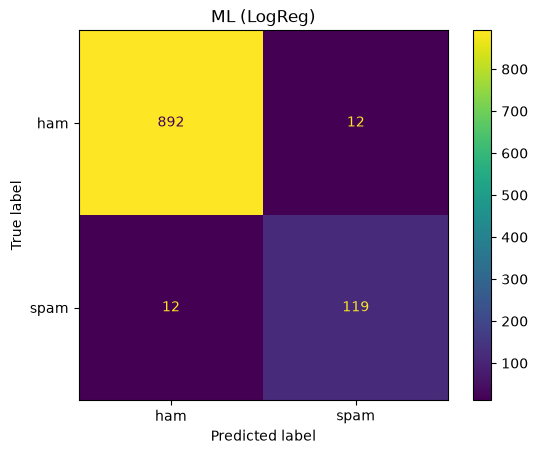

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(truth, ml_predictions)
plt.title("ML (LogReg)")
plt.show()

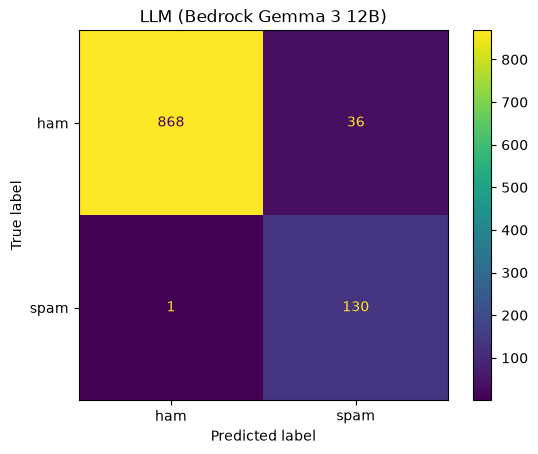

In [16]:
ConfusionMatrixDisplay.from_predictions(truth, llm_predictions, labels=["ham", "spam"])
plt.title("LLM (Bedrock Gemma 3 12B)")
plt.show()

## 12. Messages each model got wrong

In [17]:
results = test_data.copy()
results["ml"] = ml_predictions
results["llm"] = llm_predictions

results[results["ml"] != results["label"]].head(10)

,label,text,ml,llm
3692,ham,"Sir, i am waiting for your call, once free ple...",spam,spam
495,ham,Are you free now?can i call now?,spam,ham
4821,spam,Check Out Choose Your Babe Videos @ sms.shsex....,ham,spam
2770,spam,Burger King - Wanna play footy at a top stadiu...,ham,spam
1056,ham,I'm at work. Please call,spam,spam
1672,ham,Glad to see your reply.,spam,ham
3981,spam,ringtoneking 84484,ham,spam
1875,spam,Would you like to see my XXX pics they are so ...,ham,spam
4475,spam,Want explicit SEX in 30 secs? Ring 02073162414...,ham,spam
2402,spam,Babe: U want me dont u baby! Im nasty and have...,ham,spam


In [18]:
results[results["llm"] != results["label"]].head(10)

,label,text,ml,llm
4349,ham,You give us back my id proof and &lt;#&gt; r...,ham,spam
5564,ham,Ok lor... Sony ericsson salesman... I ask shuh...,ham,spam
3035,ham,Get ready for &lt;#&gt; inches of pleasure...,ham,spam
5262,ham,If anyone calls for a treadmill say you'll buy...,ham,spam
3692,ham,"Sir, i am waiting for your call, once free ple...",spam,spam
1056,ham,I'm at work. Please call,spam,spam
2048,ham,No de. But call me after some time. Ill tell y...,ham,spam
3532,ham,Prepare to be pounded every night...,ham,spam
3838,ham,Early bird! Any purchases yet?,ham,spam
2649,ham,"Hi, can i please get a &lt;#&gt; dollar loan...",ham,spam


## Notes
The ML model is the better choice when identifying spam / ham. The LLM catches every spam but it also flags normal messages as spam. 

